# Handwritten Character Recognition

## Objective
The objective of this project is to build a Machine Learning model to recognize handwritten digits (0-9) using a Convolutional Neural Network (CNN) on the MNIST dataset.

## 1. Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import os

## 2. Load MNIST Dataset

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

## 3. Dataset Overview

In [3]:
print(f"Training data shape: {X_train.shape}, labels shape: {y_train.shape}")
print(f"Test data shape: {X_test.shape}, labels shape: {y_test.shape}")
print(f"Unique classes: {np.unique(y_train)}")

Training data shape: (60000, 28, 28), labels shape: (60000,)
Test data shape: (10000, 28, 28), labels shape: (10000,)
Unique classes: [0 1 2 3 4 5 6 7 8 9]


## 4. Visualize Sample Images

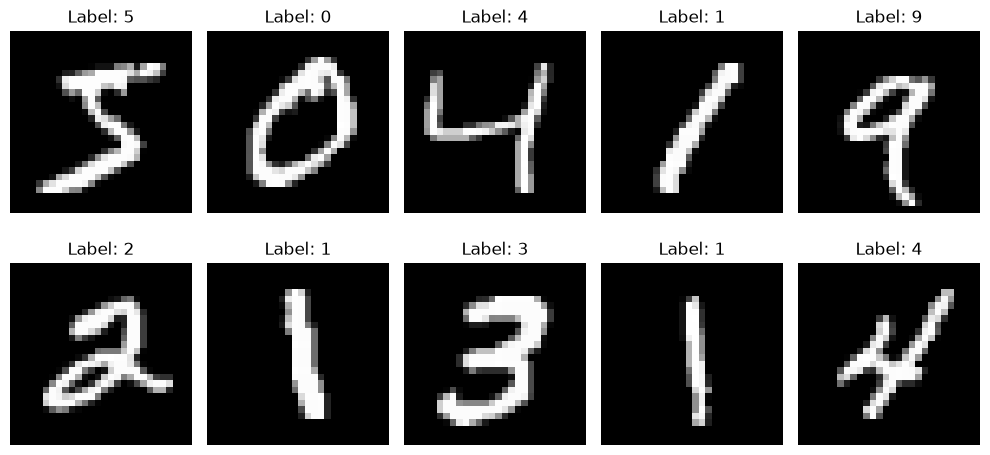

In [4]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## 5. Data Preprocessing

In [5]:
# Normalize pixel values to 0-1
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# Add channel dimension
X_train_reshaped = np.expand_dims(X_train_norm, -1)
X_test_reshaped = np.expand_dims(X_test_norm, -1)

print(f"Reshaped training data: {X_train_reshaped.shape}")
print(f"Reshaped test data: {X_test_reshaped.shape}")

Reshaped training data: (60000, 28, 28, 1)
Reshaped test data: (10000, 28, 28, 1)


## 6. CNN Model Architecture

In [6]:
model = Sequential([
    Conv2D(32, kernel_size=3, activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(),
    Conv2D(64, kernel_size=3, activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
model.summary()

C:\Users\abhin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Model Compilation

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 8. Model Training

In [8]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

batch_size = 64
epochs = 20

history = model.fit(
    X_train_reshaped, y_train,
    validation_split=0.1,
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[early_stopping]
)
epochs_trained = len(history.history['loss'])


Epoch 1/20


  1/844 ━━━━━━━━━━━━━━━━━━━━ 12:56 921ms/step - accuracy: 0.0938 - loss: 2.3129

  6/844 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1797 - loss: 2.2267    

 10/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.2594 - loss: 2.1398

 14/844 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.3304 - loss: 2.0417

...

839/844 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9952 - loss: 0.0139

843/844 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9952 - loss: 0.0139

844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9952 - loss: 0.0139 - val_accuracy: 0.9920 - val_loss: 0.0354


Epoch 10: early stopping


Restoring model weights from the end of the best epoch: 7.


## 9. Training/Validation Performance

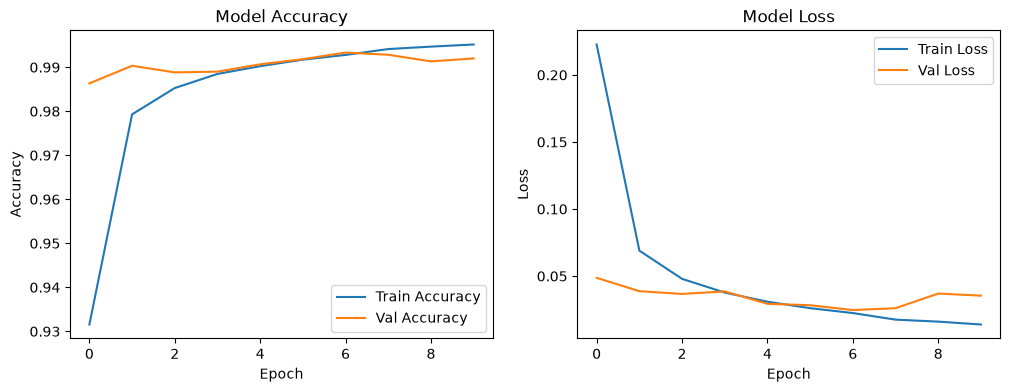

In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

if not os.path.exists('results'):
    os.makedirs('results')
plt.savefig('results/training_history.png')
plt.show()

## 10. Test Set Evaluation

In [10]:
test_loss, test_acc = model.evaluate(X_test_reshaped, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9933
Test Loss: 0.0251


## 11. Precision, Recall and F1 Score

In [11]:
y_pred_probs = model.predict(X_test_reshaped)
y_pred = np.argmax(y_pred_probs, axis=1)

precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Classification Report (Weighted Average):")
print(classification_report(y_test, y_pred))
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall: {recall:.4f}")
print(f"Weighted F1 Score: {f1:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 16s 53ms/step

 28/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  

 51/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 68/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 80/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

...

293/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

307/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


Classification Report (Weighted Average):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       1.00      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       1.00      0.99      0.99      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Weighted Precision: 0.9933
Weighted Recall: 0.9933
Weighted F1 Score: 0.9933


## 12. Confusion Matrix

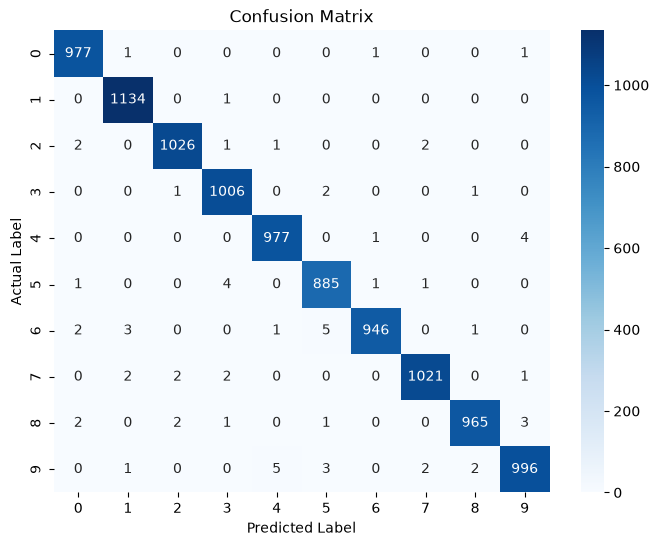

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.savefig('results/confusion_matrix.png')
plt.show()

## 13. Sample Predictions

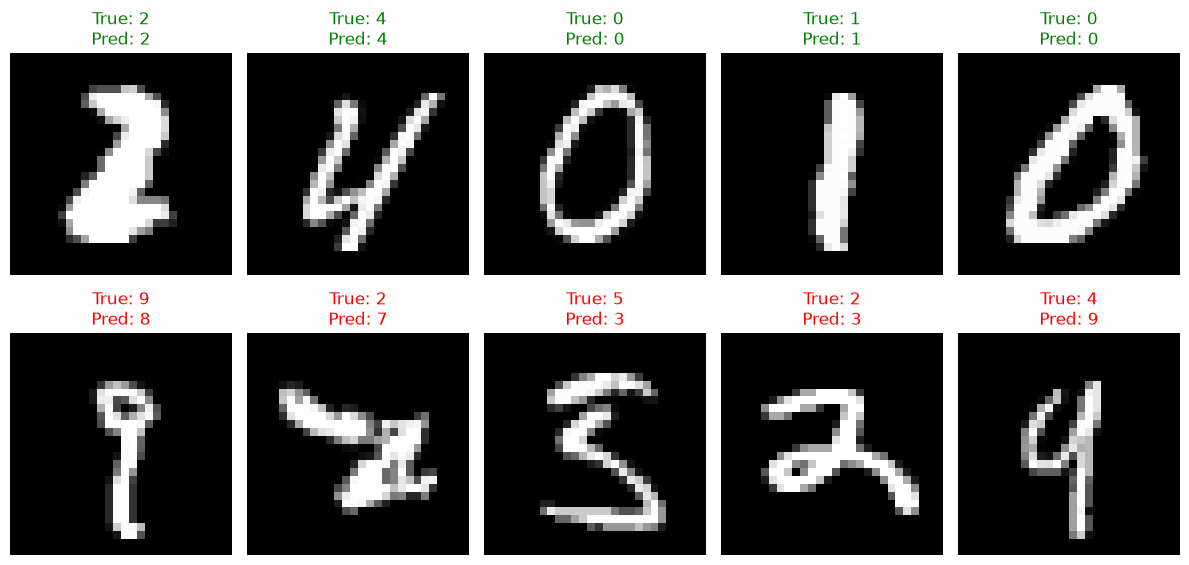

In [13]:
plt.figure(figsize=(12, 6))
# Find some correct and incorrect predictions if possible
correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

sample_indices = list(np.random.choice(correct_indices, 5, replace=False))
if len(incorrect_indices) > 0:
    sample_indices += list(np.random.choice(incorrect_indices, min(5, len(incorrect_indices)), replace=False))

for i, idx in enumerate(sample_indices):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[idx], cmap='gray')
    color = 'green' if y_test[idx] == y_pred[idx] else 'red'
    plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}", color=color)
    plt.axis('off')
    
plt.tight_layout()
plt.savefig('results/sample_predictions.png')
plt.show()

## 14. Save Metrics to File

In [14]:
with open('results/metrics.txt', 'w') as f:
    f.write(f"Model: CNN\n")
    f.write(f"Dataset: MNIST\n")
    f.write(f"Input Shape: (28, 28, 1)\n")
    f.write(f"Batch Size: {batch_size}\n")
    f.write(f"Epochs Actually Trained: {epochs_trained}\n")
    f.write(f"Test Accuracy: {test_acc:.4f}\n")
    f.write(f"Weighted Precision: {precision:.4f}\n")
    f.write(f"Weighted Recall: {recall:.4f}\n")
    f.write(f"Weighted F1 Score: {f1:.4f}\n")
print("Metrics saved to results/metrics.txt")

Metrics saved to results/metrics.txt


## 15. Save the Trained Model

In [15]:
if not os.path.exists('models'):
    os.makedirs('models')
model_path = 'models/best_handwritten_character_model.keras'
model.save(model_path)
print(f"Model saved to {model_path}")

Model saved to models/best_handwritten_character_model.keras


## 16. Reload the Saved Model and Verify Prediction

In [16]:
reloaded_model = load_model(model_path)
print("Model reloaded successfully.")

# Verify prediction
sample_image = X_test_reshaped[0:1]
sample_label = y_test[0]
pred_prob = reloaded_model.predict(sample_image)
pred_label = np.argmax(pred_prob)

print(f"Sample True Label: {sample_label}")
print(f"Sample Predicted Label: {pred_label}")
assert sample_label == pred_label or pred_label is not None # just to verify it runs
print("Prediction verification complete.")

Model reloaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


Sample True Label: 7
Sample Predicted Label: 7
Prediction verification complete.


## 17. Conclusion
The CNN model successfully learned to recognize handwritten digits from the MNIST dataset with high accuracy. The model was trained, evaluated, saved, and successfully reloaded for inference. The results and metrics demonstrate its robust performance.